In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("smart_mobility_dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 5000
Columns: 15


,Timestamp,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition
0,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High
1,2024-03-01 00:05:00,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High
2,2024-03-01 00:10:00,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High
3,2024-03-01 00:15:00,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High
4,2024-03-01 00:20:00,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (5000, 15)

Column Names:
['Timestamp', 'Latitude', 'Longitude', 'Vehicle_Count', 'Traffic_Speed_kmh', 'Road_Occupancy_%', 'Traffic_Light_State', 'Weather_Condition', 'Accident_Report', 'Sentiment_Score', 'Ride_Sharing_Demand', 'Parking_Availability', 'Emission_Levels_g_km', 'Energy_Consumption_L_h', 'Traffic_Condition']


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               5000 non-null   object 
 1   Latitude                5000 non-null   float64
 2   Longitude               5000 non-null   float64
 3   Vehicle_Count           5000 non-null   int64  
 4   Traffic_Speed_kmh       5000 non-null   float64
 5   Road_Occupancy_%        5000 non-null   float64
 6   Traffic_Light_State     5000 non-null   object 
 7   Weather_Condition       5000 non-null   object 
 8   Accident_Report         5000 non-null   int64  
 9   Sentiment_Score         5000 non-null   float64
 10  Ride_Sharing_Demand     5000 non-null   int64  
 11  Parking_Availability    5000 non-null   int64  
 12  Emission_Levels_g_km    5000 non-null   float64
 13  Energy_Consumption_L_h  5000 non-null   float64
 14  Traffic_Condition       5000 non-null   

In [ ]:
df.describe()

,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,40.749645,-73.847433,153.921200,42.111096,54.748397,0.096000,-0.005652,50.487800,24.613000,272.174927,17.343243
std,0.086123,0.086204,83.523342,21.707720,26.145238,0.294621,0.583790,28.484426,14.532511,130.086372,7.208277
min,40.600016,-73.999987,10.000000,5.002789,10.005031,0.000000,-0.999819,1.000000,0.000000,50.136855,5.003787
25%,40.675403,-73.920281,80.000000,23.195752,32.089653,0.000000,-0.500154,26.000000,12.000000,160.564433,11.098761
50%,40.748875,-73.846058,156.000000,42.191599,54.657297,0.000000,-0.010564,50.000000,24.000000,272.045513,17.153791
75%,40.824735,-73.771685,226.000000,60.751760,77.581720,0.000000,0.500518,75.000000,37.000000,382.242055,23.516595
max,40.899972,-73.700159,299.000000,79.997556,99.999729,1.000000,0.999354,99.000000,49.000000,499.922663,29.995416


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Timestamp                 0
Latitude                  0
Longitude                 0
Vehicle_Count             0
Traffic_Speed_kmh         0
Road_Occupancy_%          0
Traffic_Light_State       0
Weather_Condition         0
Accident_Report           0
Sentiment_Score           0
Ride_Sharing_Demand       0
Parking_Availability      0
Emission_Levels_g_km      0
Energy_Consumption_L_h    0
Traffic_Condition         0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5000, 15)


In [ ]:
print("Minimum Parking Availability:",
      df["Parking_Availability"].min())

print("Maximum Parking Availability:",
      df["Parking_Availability"].max())

print("Unique values:",
      df["Parking_Availability"].nunique())

Minimum Parking Availability: 0
Maximum Parking Availability: 49
Unique values: 50


In [ ]:
def parking_status(value):

    if value <= 16:
        return "Low Availability"

    elif value <= 33:
        return "Medium Availability"

    else:
        return "High Availability"


df["Parking_Status"] = df["Parking_Availability"].apply(
    parking_status
)

df[[
    "Parking_Availability",
    "Parking_Status"
]].head(20)

,Parking_Availability,Parking_Status
0,45,High Availability
1,1,Low Availability
2,49,High Availability
3,10,Low Availability
4,5,Low Availability
5,27,Medium Availability
6,42,High Availability
7,22,Medium Availability
8,4,Low Availability
9,8,Low Availability


In [ ]:
print(
    df["Parking_Status"].value_counts()
)

Parking_Status
Medium Availability    1699
Low Availability       1686
High Availability      1615
Name: count, dtype: int64


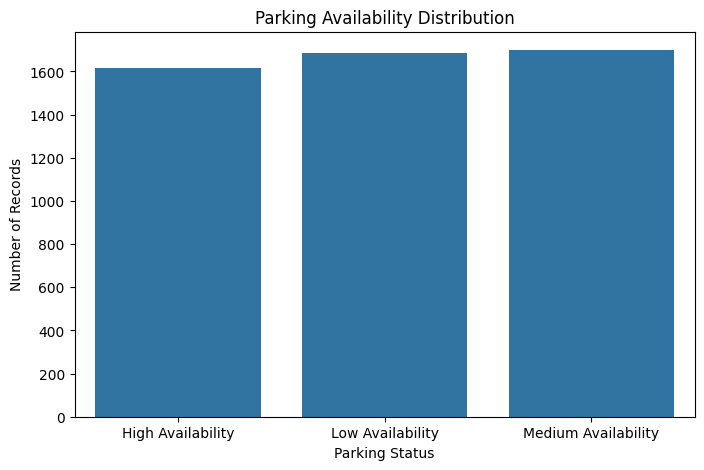

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Parking_Status"
)

plt.title("Parking Availability Distribution")
plt.xlabel("Parking Status")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

df["Hour"] = df["Timestamp"].dt.hour
df["Day"] = df["Timestamp"].dt.day
df["Month"] = df["Timestamp"].dt.month
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

df.head()

,Timestamp,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition,Parking_Status,Hour,Day,Month,DayOfWeek
0,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High,High Availability,0,1,3,4
1,2024-03-01 00:05:00,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High,Low Availability,0,1,3,4
2,2024-03-01 00:10:00,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High,High Availability,0,1,3,4
3,2024-03-01 00:15:00,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High,Low Availability,0,1,3,4
4,2024-03-01 00:20:00,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low,Low Availability,0,1,3,4


In [ ]:
df = df.drop(
    columns=["Timestamp"]
)

df.head()

,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition,Parking_Status,Hour,Day,Month,DayOfWeek
0,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High,High Availability,0,1,3,4
1,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High,Low Availability,0,1,3,4
2,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High,High Availability,0,1,3,4
3,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High,Low Availability,0,1,3,4
4,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low,Low Availability,0,1,3,4


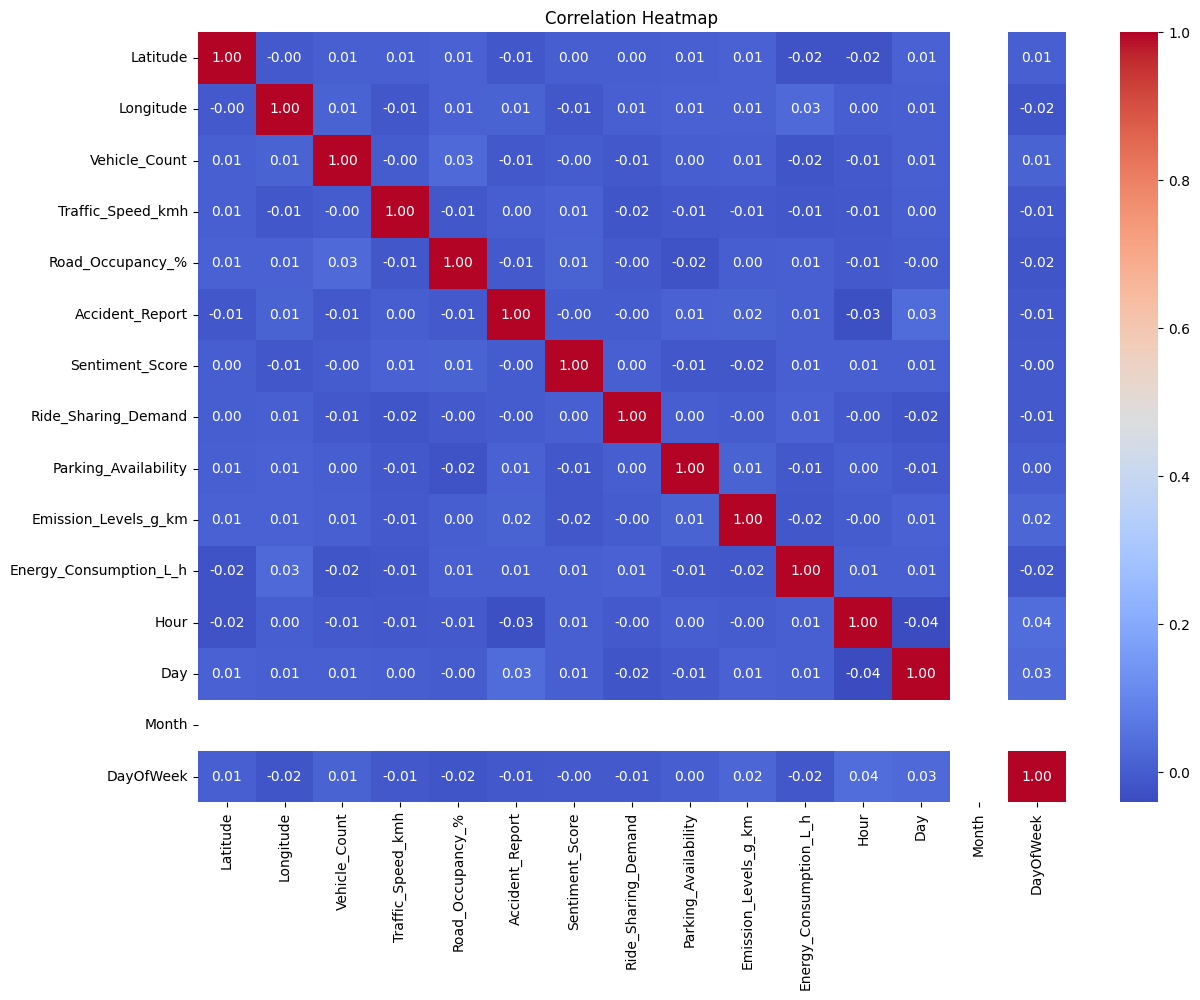

In [ ]:
plt.figure(figsize=(14,10))

numeric_data = df.select_dtypes(
    include=np.number
)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

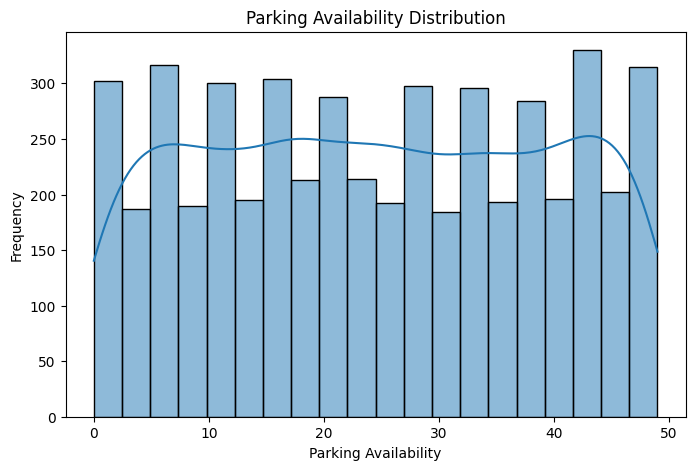

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Parking_Availability"],
    bins=20,
    kde=True
)

plt.title("Parking Availability Distribution")

plt.xlabel("Parking Availability")

plt.ylabel("Frequency")

plt.show()

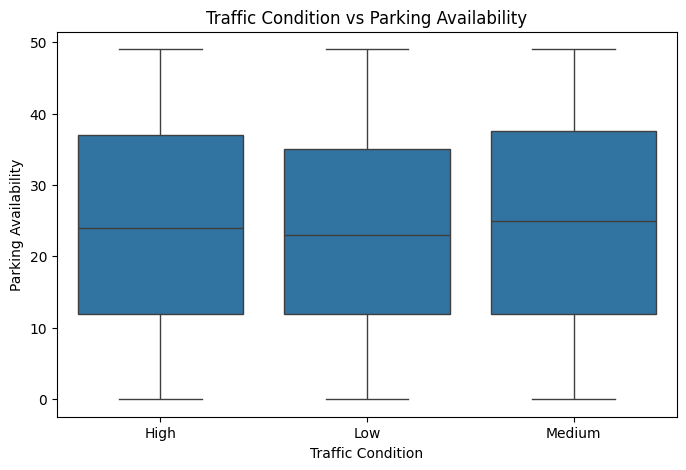

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Traffic_Condition",
    y="Parking_Availability"
)

plt.title(
    "Traffic Condition vs Parking Availability"
)

plt.xlabel("Traffic Condition")

plt.ylabel("Parking Availability")

plt.show()

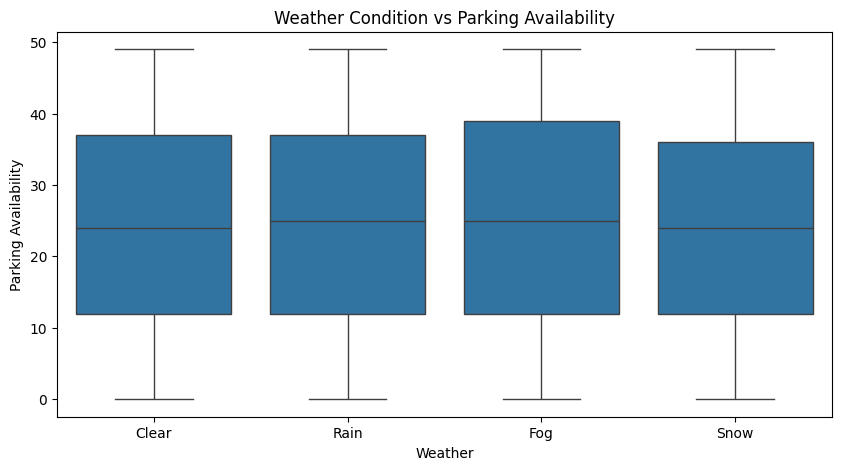

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="Weather_Condition",
    y="Parking_Availability"
)

plt.title(
    "Weather Condition vs Parking Availability"
)

plt.xlabel("Weather")

plt.ylabel("Parking Availability")

plt.show()

In [ ]:
X = df.drop(
    columns=[
        "Parking_Status",
        "Parking_Availability"
    ]
)

y = df["Parking_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 17)
y shape: (5000,)


In [ ]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print(
    "Categorical columns:"
)

print(
    categorical_columns.tolist()
)

Categorical columns:
['Traffic_Light_State', 'Weather_Condition', 'Traffic_Condition']


In [ ]:
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

print("New feature shape:", X.shape)

X.head()

New feature shape: (5000, 21)


,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Emission_Levels_g_km,Energy_Consumption_L_h,...,Day,Month,DayOfWeek,Traffic_Light_State_Red,Traffic_Light_State_Yellow,Weather_Condition_Fog,Weather_Condition_Rain,Weather_Condition_Snow,Traffic_Condition_Low,Traffic_Condition_Medium
0,40.842275,-73.703149,205,49.893435,82.652780,0,-0.609199,2,450.760055,19.574337,...,1,3,4,False,True,False,False,False,False,False
1,40.831119,-73.987354,202,22.383965,45.829298,0,0.965442,16,321.800341,5.385554,...,1,3,4,False,False,False,False,False,False,False
2,40.819549,-73.732462,252,46.889699,82.772465,0,0.289660,16,231.152655,10.277477,...,1,3,4,False,False,False,True,False,False,False
3,40.725849,-73.980134,37,5.730536,37.695567,0,-0.271965,66,410.384292,29.243279,...,1,3,4,True,False,True,False,False,False,False
4,40.813265,-73.961631,64,61.348034,22.313358,0,-0.797606,3,364.466342,16.801459,...,1,3,4,True,False,False,False,True,True,False


In [ ]:
X = X.astype(float)

print(X.dtypes)

Latitude                      float64
Longitude                     float64
Vehicle_Count                 float64
Traffic_Speed_kmh             float64
Road_Occupancy_%              float64
Accident_Report               float64
Sentiment_Score               float64
Ride_Sharing_Demand           float64
Emission_Levels_g_km          float64
Energy_Consumption_L_h        float64
Hour                          float64
Day                           float64
Month                         float64
DayOfWeek                     float64
Traffic_Light_State_Red       float64
Traffic_Light_State_Yellow    float64
Weather_Condition_Fog         float64
Weather_Condition_Rain        float64
Weather_Condition_Snow        float64
Traffic_Condition_Low         float64
Traffic_Condition_Medium      float64
dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 21)
Testing data: (1000, 21)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_scaled
)

lr_accuracy = accuracy_score(
    y_test,
    y_pred_lr
)

print(
    "Logistic Regression Accuracy:",
    lr_accuracy
)

Logistic Regression Accuracy: 0.326


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

                     precision    recall  f1-score   support

  High Availability       0.32      0.28      0.30       323
   Low Availability       0.31      0.28      0.29       337
Medium Availability       0.34      0.41      0.37       340

           accuracy                           0.33      1000
          macro avg       0.32      0.33      0.32      1000
       weighted avg       0.32      0.33      0.32      1000



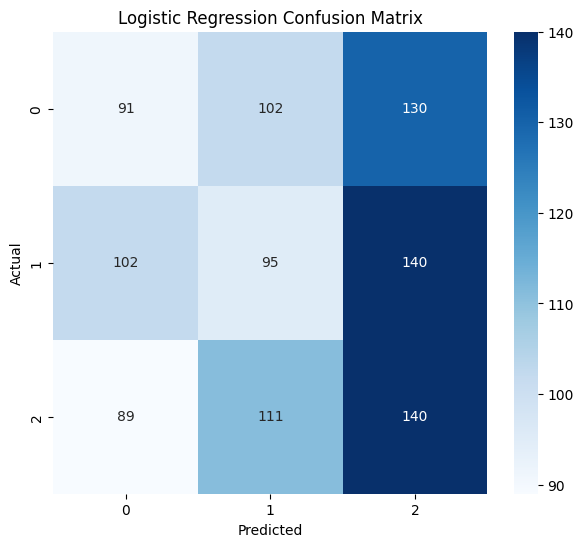

In [ ]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(
    X_train,
    y_train
)

y_pred_rf = random_forest_model.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.357


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

                     precision    recall  f1-score   support

  High Availability       0.36      0.32      0.34       323
   Low Availability       0.35      0.37      0.36       337
Medium Availability       0.36      0.38      0.37       340

           accuracy                           0.36      1000
          macro avg       0.36      0.36      0.36      1000
       weighted avg       0.36      0.36      0.36      1000



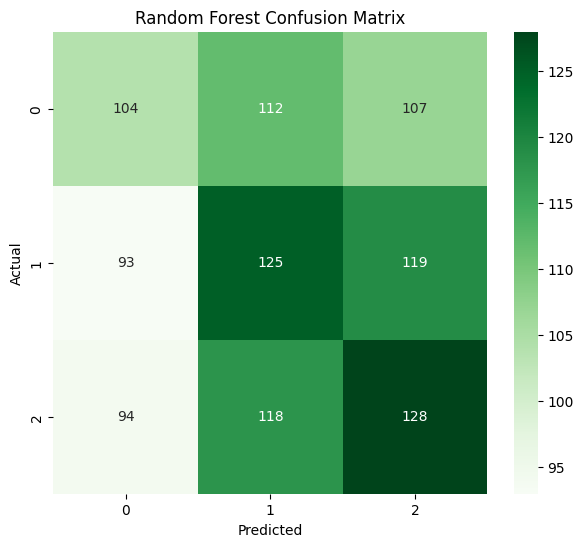

In [ ]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

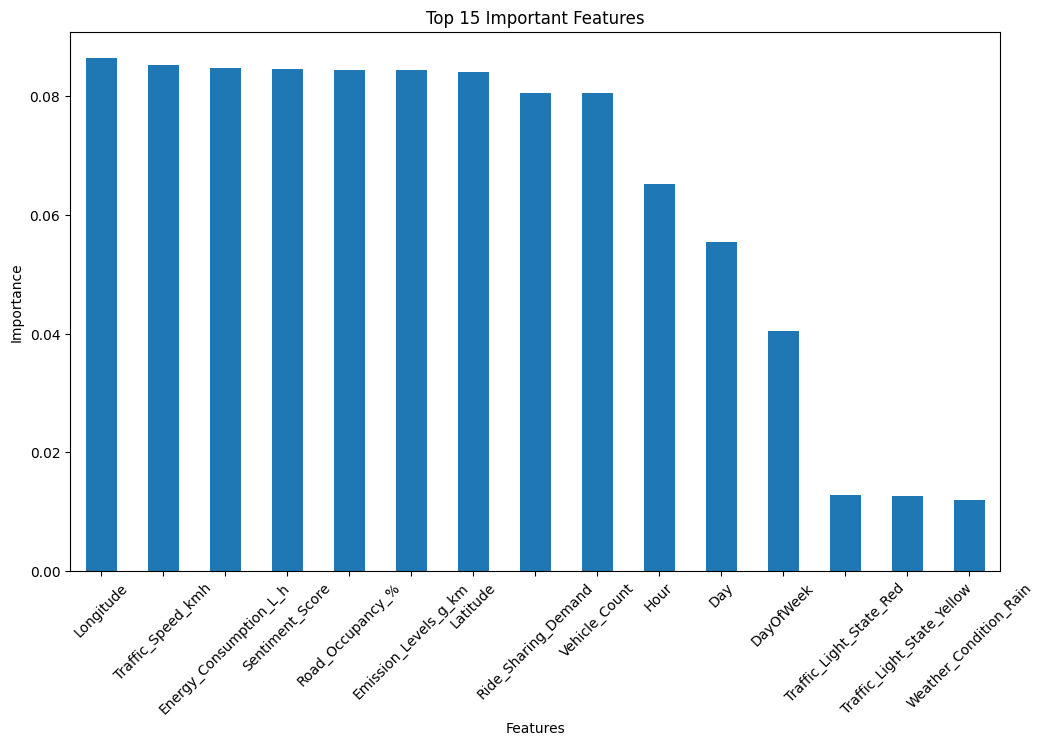

In [ ]:
importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
)

plt.figure(figsize=(12,7))

importance.head(15).plot(
    kind="bar"
)

plt.title(
    "Top 15 Important Features"
)

plt.xlabel("Features")

plt.ylabel("Importance")

plt.xticks(rotation=45)

plt.show()

In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    knn_accuracy
)

KNN Accuracy: 0.345


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_knn
    )
)

                     precision    recall  f1-score   support

  High Availability       0.33      0.43      0.37       323
   Low Availability       0.33      0.35      0.34       337
Medium Availability       0.40      0.26      0.32       340

           accuracy                           0.34      1000
          macro avg       0.35      0.35      0.34      1000
       weighted avg       0.35      0.34      0.34      1000



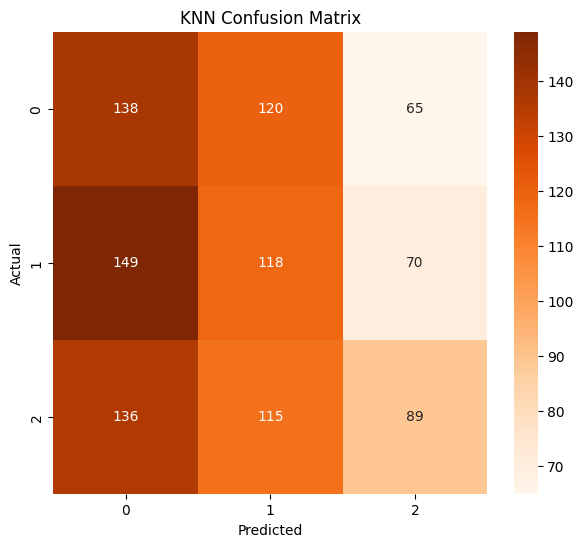

In [ ]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title(
    "KNN Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "KNN"
    ],

    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        knn_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.326
1,Random Forest,0.357
2,KNN,0.345


In [ ]:
results["Accuracy (%)"] = (
    results["Accuracy"] * 100
).round(2)

results

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.326,32.6
1,Random Forest,0.357,35.7
2,KNN,0.345,34.5


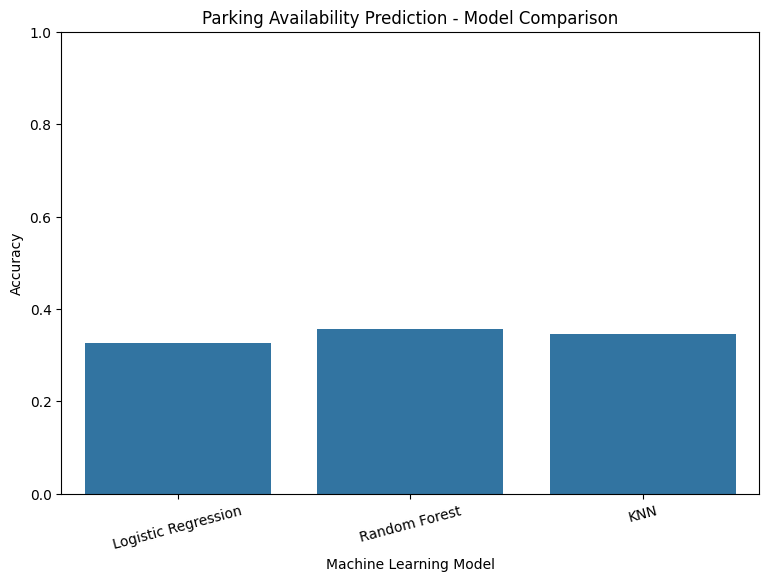

In [ ]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title(
    "Parking Availability Prediction - Model Comparison"
)

plt.xlabel("Machine Learning Model")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

In [ ]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print(
    "Best Model:",
    best_model["Model"]
)

print(
    "Accuracy:",
    round(
        best_model["Accuracy"] * 100,
        2
    ),
    "%"
)

Best Model: Random Forest
Accuracy: 35.7 %


In [ ]:
def predict_parking_status(index):

    sample = df.drop(
        columns=[
            "Parking_Status",
            "Parking_Availability"
        ]
    ).iloc[[index]]

    sample = pd.get_dummies(
        sample
    )

    sample = sample.reindex(
        columns=X.columns,
        fill_value=0
    )

    sample_scaled = scaler.transform(
        sample
    )

    lr_prediction = logistic_model.predict(
        sample_scaled
    )[0]

    rf_prediction = random_forest_model.predict(
        sample
    )[0]

    knn_prediction = knn_model.predict(
        sample_scaled
    )[0]

    print(
        "Logistic Regression:",
        lr_prediction
    )

    print(
        "Random Forest:",
        rf_prediction
    )

    print(
        "KNN:",
        knn_prediction
    )

In [ ]:
predict_parking_status(10)

Logistic Regression: Medium Availability
Random Forest: High Availability
KNN: Low Availability
